# University Student Dropout Early Warning System
## Project Overview
This project builds an end-to-end Machine Learning classification model to predict university student dropout risk.
By identifying high-risk students early using socio-demographic indicators and early academic records (Semester 1 & 2),
academic counselors and administrators can proactively intervene with timely academic and financial assistance.


## 1. Import Libraries & Dataset
Import the necessary packages for data manipulation, exploratory data analysis, machine learning modeling, and performance evaluation.

In [33]:
# Import core libraries
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    mutual_info_score, 
    roc_auc_score, 
    roc_curve, 
    precision_recall_curve, 
    average_precision_score, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    confusion_matrix
)
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Load dataset from data directory
df = pd.read_csv('../data/data.csv', sep=';')

## 2. Data Exploration & Data Preprocessing
Perform initial data inspection, standardize column headers, check for missing values, and prepare the binary target variable.

### 2.1. Data Cleaning & Target Preparation
Standardize all column headers to lowercase `snake_case`, verify that there are no missing values or duplicate records, filter out active students (`Enrolled`), and encode the target variable into binary: `1` for `Dropout` and `0` for `Graduate`.

In [ ]:
# 1. Standardize column names to snake_case
def cleaning_data(data):
    data = data.copy()
    data.columns = [re.sub(r'[^a-z0-9]+', '_', col.lower()).strip('_') for col in data.columns]
    return data

df = cleaning_data(df)

# 2. Check for missing values and duplicate rows
print("Missing values across columns:", df.isnull().sum().max())
print("Duplicate rows count:", df.duplicated().sum())

# 3. Filter only 'Dropout' and 'Graduate' (exclude active 'Enrolled' students)
df = df[df['target'].isin(['Dropout', 'Graduate'])].reset_index(drop=True)

# 4. Encode target as binary: Dropout = 1, Graduate = 0
df['target'] = (df['target'] == 'Dropout').astype(int)

print("\nDataset shape after filtering:", len(df))
print(df['target'].value_counts())

Missing values across columns: 0
Duplicate rows count          : 0

Dataset shape after filtering: 3630
target
0    2209
1    1421
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)
Analyze the target variable distribution, compute Mutual Information for categorical variables, analyze correlations for numerical features, and establish feature selection criteria.

### 3.1. Target Analysis (Class Distribution & Imbalance Check)
Evaluate the proportion of Graduate vs. Dropout students to check for potential class imbalance.

In [ ]:
# Compute target class distribution
class_counts = df['target'].value_counts()
class_percentages = df['target'].value_counts(normalize=True) * 100

print("--- TARGET CLASS DISTRIBUTION ---")
print(f"Graduate (0) : {class_counts[0]} students ({class_percentages[0]:.2f}%)")
print(f"Dropout (1)  : {class_counts[1]} students ({class_percentages[1]:.2f}%)")
print(f"Ratio Graduate vs Dropout = {class_counts[0] / class_counts[1]:.2f} : 1")

--- TARGET CLASS DISTRIBUTION ---
Graduate (0) : 2209 students (60.85%)
Dropout (1)  : 1421 students (39.15%)
Ratio Graduate vs Dropout = 1.55 : 1


### 3.2. Categorical Features Analysis
Evaluate the dropout rate across categorical indicators and compute Mutual Information (MI) scores to quantify each feature's predictive power relative to the target.

In [36]:
# List of categorical features
categorical = [
    'marital_status', 'application_mode', 'course', 
    'daytime_evening_attendance', 'previous_qualification', 
    'nacionality', 'mother_s_qualification', 'father_s_qualification', 
    'mother_s_occupation', 'father_s_occupation', 'displaced', 
    'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 
    'gender', 'scholarship_holder', 'international'
]

# 1. Dropout rate across key indicators
for col in ['tuition_fees_up_to_date', 'debtor', 'scholarship_holder', 'gender']:
    print(f"\n--- Dropout Rate per {col} ---")
    print(df.groupby(col)['target'].agg(['count', 'mean']).rename(columns={'mean': 'dropout_rate'}))

# 2. Compute Mutual Information score with target
def compute_mi(series):
    return mutual_info_score(series, df['target'])
    
mi_scores = df[categorical].apply(compute_mi).sort_values(ascending=False)
print("\n--- Mutual Information Scores with Target ---")
print(mi_scores)


--- Dropout Rate per tuition_fees_up_to_date ---
                         count  dropout_rate
tuition_fees_up_to_date                     
0                          486      0.940329
1                         3144      0.306616

--- Dropout Rate per debtor ---
        count  dropout_rate
debtor                     
0        3217      0.344731
1         413      0.755448

--- Dropout Rate per scholarship_holder ---
                    count  dropout_rate
scholarship_holder                     
0                    2661      0.483653
1                     969      0.138287

--- Dropout Rate per gender ---
        count  dropout_rate
gender                     
0        2381      0.302394
1        1249      0.561249

--- Mutual Information Scores with Target ---
tuition_fees_up_to_date       0.105286
course                        0.063603
application_mode              0.054538
scholarship_holder            0.054403
debtor                        0.035268
gender                        0.0

### 3.3. Numerical Features Analysis
Compare the mean values of key academic indicators between graduates and dropouts, and compute Pearson correlation coefficients with the target variable.

In [37]:
# List of numerical features
numerical = [
    'application_order', 'previous_qualification_grade', 'admission_grade', 
    'age_at_enrollment', 'curricular_units_1st_sem_credited', 
    'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 
    'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 
    'curricular_units_1st_sem_without_evaluations',
    'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 
    'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 
    'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 
    'unemployment_rate', 'inflation_rate', 'gdp'
]

print("--- Mean Comparisons between Graduate (0) and Dropout (1) ---")
print(df.groupby('target')[['age_at_enrollment', 'admission_grade', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade']].mean())

correlations = df[numerical + ['target']].corr()['target'].drop('target').sort_values()
print("\n--- Numerical Feature Correlations with Target (Dropout) ---")
print(correlations)

--- Mean Comparisons between Graduate (0) and Dropout (1) ---
        age_at_enrollment  admission_grade  curricular_units_1st_sem_approved  \
target                                                                          
0               21.783612       128.794432                           6.232232   
1               26.068966       124.961365                           2.551724   

        curricular_units_1st_sem_grade  
target                                  
0                            12.643655  
1                             7.256656  

--- Numerical Feature Correlations with Target (Dropout) ---
curricular_units_2nd_sem_approved              -0.653995
curricular_units_2nd_sem_grade                 -0.605350
curricular_units_1st_sem_approved              -0.554881
curricular_units_1st_sem_grade                 -0.519927
curricular_units_2nd_sem_enrolled              -0.182897
curricular_units_1st_sem_enrolled              -0.161074
admission_grade                              

### 3.4. EDA Insights & Feature Selection Analysis

Based on the Exploratory Data Analysis, key findings regarding student dropout risk, feature relevance, and outlier handling are summarized below:

#### 1. Key Domain Findings
* **Financial Indicators (Critical Drivers):**
  - `tuition_fees_up_to_date`: Students who are behind on tuition payments have a **94.0% dropout rate** (compared to only 30.7% for those whose fees are up to date). This feature exhibits the highest Mutual Information score (**0.105**).
  - `debtor`: Students with recorded debt have a **75.5% dropout rate** versus 34.5% for non-debtors.
  - `scholarship_holder`: Scholarship recipients demonstrate high retention, with a low dropout rate of **13.8%** (versus 48.4% for non-recipients).
* **Academic Performance in Semesters 1 & 2:**
  - Curricular units approved (`curricular_units_2nd_sem_approved` and `curricular_units_1st_sem_approved`) and unit grades exhibit strong negative correlations with dropout ($r = -0.52$ to $-0.65$).
  - Graduating students pass on average **6.2 units** in the 1st semester with an average grade of **12.6**, whereas dropouts pass only **2.5 units** with an average grade of **7.3**.
* **Demographics:**
  - `age_at_enrollment` is positively correlated with dropout ($r = +0.27$). Dropouts enroll at an older average age (**26.1 years**) compared to graduates (**21.8 years**).
  - Male students exhibit a higher dropout rate (**56.1%**) than female students (**30.2%**).

---

#### 2. Feature Selection & Dropping Considerations
During the categorical (Mutual Information) and numerical (correlation) analyses, we evaluated which features are informative and which provide negligible value:

* **Informative Features Selected for Modeling:**
  - **Financial:** `tuition_fees_up_to_date`, `debtor`, `scholarship_holder`.
  - **Academic Records:** `curricular_units_1st_sem_approved`, `curricular_units_1st_sem_grade`, `curricular_units_2nd_sem_approved`, `curricular_units_2nd_sem_grade`, `admission_grade`, `previous_qualification_grade`.
  - **Demographic & Administrative:** `age_at_enrollment`, `course`, `application_mode`, `gender`.

* **Uninformative / Low-Variance Features (Candidates for Dropping):**
  - **Near-Zero Mutual Information:** `educational_special_needs` ($MI = 0.000026$), `international` ($MI = 0.000019$), `daytime_evening_attendance` ($MI = 0.0035$), and `nacionality` ($MI = 0.0035$) carry almost no statistical signal regarding dropout likelihood due to extreme class sparsity.
  - **Near-Zero Correlation:** Macroeconomic indicators such as `unemployment_rate` ($r = -0.004$) and `inflation_rate` ($r = +0.030$) show negligible linear relationship with individual student dropout decisions.

* **Modeling Strategy Decision:**
  - In our training pipeline, we initially retain all 36 candidate features because regularized linear models (`LogisticRegression` with parameter `C`) and tree-based ensembles (`RandomForestClassifier`, `XGBClassifier`) automatically apply shrinkage and feature gating. In addition, the feature space ($p = 36$) is relatively small compared to sample size ($N = 2,178$), presenting negligible risk of dimensionality explosion. However, for a streamlined production deployment, the 4-5 low-signal features identified above can be safely excluded to reduce payload size without hurting accuracy.

---

#### 3. Outlier Handling & Justification
* **Observation of Extreme Values:**
  - Several numerical variables exhibit wide spreads and extreme values, notably `age_at_enrollment` (ranging up to 70 years) and academic records where students earned zero credits or zero evaluation grades.
* **Retention Rationale (Why Outliers are Not Dropped):**
  - **Domain Reality vs. Errors:** These values represent legitimate real-world phenomena rather than data entry anomalies or measurement errors. Older students reflect non-traditional working adults, and zero passed credits capture students who suffered complete first-year academic withdrawal.
  - **Preventing Survivorship Bias:** Applying automated filtering (such as IQR trimming or Z-score thresholds) would discard the most vulnerable student cohorts—the exact individuals our early warning system is designed to detect and support.
  - **Model Invariance:** The primary algorithms selected for this project (**Random Forest** and **XGBoost**) are decision-tree ensembles that evaluate non-linear split points independently of absolute scale, making them inherently robust to extreme values.


## 4. Validation Framework
Split the dataset into **Train (60%)**, **Validation (20%)**, and **Test (20%)** subsets using stratified sampling to preserve the 1.55:1 class ratio across all splits. Then, transform the feature dictionaries into numerical matrices using `DictVectorizer`.

In [38]:
# 1. Split into Train_Full (80%) and Test (20%)
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])

# 2. Split Train_Full into Train (60%) and Validation (20%)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=42, stratify=df_train_full['target'])

# Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Extract target values
y_train = df_train['target'].values
y_val = df_val['target'].values
y_test = df_test['target'].values

# Remove target from feature matrices
del df_train['target']
del df_val['target']
del df_test['target']

print(f"Train set size      : {len(df_train)} ({(len(df_train)/len(df))*100:.0f}%)")
print(f"Validation set size : {len(df_val)} ({(len(df_val)/len(df))*100:.0f}%)")
print(f"Test set size       : {len(df_test)} ({(len(df_test)/len(df))*100:.0f}%)")

# Vectorize features using DictVectorizer
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape  : {X_val.shape}")

Train set size      : 2178 (60%)
Validation set size : 726 (20%)
Test set size       : 726 (20%)
X_train shape: (2178, 36)
X_val shape  : (726, 36)


## 5. Model Training & Hyperparameter Tuning
Train and evaluate three distinct classification models, tuning their parameters to optimize the **ROC-AUC** score:
1. **Logistic Regression** (Linear baseline)
2. **Random Forest Classifier** (Bagging tree ensemble)
3. **XGBoost Classifier** (Boosting tree ensemble)

### 5.1. Model 1 (Baseline): Logistic Regression
Train a baseline Logistic Regression model and tune the regularization strength parameter `C` using `GridSearchCV` with 5-Fold Cross-Validation, optimizing for **ROC-AUC**.

In [39]:
# Logistic Regression with GridSearchCV
param_grid_lr = {'C': [0.001, 0.01, 0.1, 1.0, 10.0]}

grid_lr = GridSearchCV(
    estimator=LogisticRegression(solver='liblinear', max_iter=1000, random_state=42),
    param_grid=param_grid_lr,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_lr.fit(X_train, y_train)

best_lr = grid_lr.best_estimator_
y_pred_val_lr = best_lr.predict_proba(X_val)[:, 1]
val_auc_lr = roc_auc_score(y_val, y_pred_val_lr)

print(f"Best LR CV ROC-AUC    : {grid_lr.best_score_:.4f}")
print(f"Best LR Hyperparameters : {grid_lr.best_params_}")
print(f"Validation Set ROC-AUC  : {val_auc_lr:.4f}")

Best LR CV ROC-AUC    : 0.9452
Best LR Hyperparameters : {'C': 0.1}
Validation Set ROC-AUC  : 0.9455


### 5.2. Model 2: Random Forest Classifier
Tune a Random Forest ensemble across tree depth (`max_depth`) and number of trees (`n_estimators`) using `GridSearchCV` with 5-Fold Cross-Validation.

In [40]:
# Random Forest with GridSearchCV
param_grid_rf = {
    'max_depth': [5, 10, 15],
    'n_estimators': [50, 100, 150]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
y_pred_val_rf = best_rf.predict_proba(X_val)[:, 1]
val_auc_rf = roc_auc_score(y_val, y_pred_val_rf)

print(f"Best RF CV ROC-AUC    : {grid_rf.best_score_:.4f}")
print(f"Best RF Hyperparameters : {grid_rf.best_params_}")
print(f"Validation Set ROC-AUC  : {val_auc_rf:.4f}")

Best RF CV ROC-AUC    : 0.9455
Best RF Hyperparameters : {'max_depth': 15, 'n_estimators': 150}
Validation Set ROC-AUC  : 0.9450


### 5.3. Model 3: XGBoost Classifier
Tune an XGBoost gradient boosting ensemble across learning rate (`learning_rate`) and maximum depth (`max_depth`) using `GridSearchCV` with 5-Fold Cross-Validation.

In [41]:
# XGBoost with GridSearchCV
param_grid_xgb = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'n_estimators': [100]
}

grid_xgb = GridSearchCV(
    estimator=XGBClassifier(eval_metric='logloss', random_state=42),
    param_grid=param_grid_xgb,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_xgb.fit(X_train, y_train)

best_xgb = grid_xgb.best_estimator_
y_pred_val_xgb = best_xgb.predict_proba(X_val)[:, 1]
val_auc_xgb = roc_auc_score(y_val, y_pred_val_xgb)

print(f"Best XGB CV ROC-AUC    : {grid_xgb.best_score_:.4f}")
print(f"Best XGB Hyperparameters : {grid_xgb.best_params_}")
print(f"Validation Set ROC-AUC   : {val_auc_xgb:.4f}")

Best XGB CV ROC-AUC    : 0.9492
Best XGB Hyperparameters : {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
Validation Set ROC-AUC   : 0.9436


## 6. Model Comparison & Final Evaluation
In this section, we compare the tuned classification models, visualize their comparative performance, evaluate generalization on the unseen test set, and summarize key institutional conclusions.

### 6.1. Performance Comparison Results (Tabular Evaluation)
Compare all tuned candidate models across multiple classification metrics (**ROC-AUC, Accuracy, Precision, Recall, and F1-Score**) on the Validation Set.
Then retrain the champion model on the complete training data (`Train + Validation`) and evaluate final generalization performance on the Test Set in a clean, structured table.

In [42]:
# 1. Validation Predictions (Binary and Probabilities for all models)
y_pred_bin_lr = (y_pred_val_lr >= 0.5).astype(int)
y_pred_bin_rf = (y_pred_val_rf >= 0.5).astype(int)
y_pred_bin_xgb = (y_pred_val_xgb >= 0.5).astype(int)

# 2. Multi-Metric Validation Set Comparison Table
val_comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression (Tuned)",
        "ROC-AUC": roc_auc_score(y_val, y_pred_val_lr),
        "Accuracy": accuracy_score(y_val, y_pred_bin_lr),
        "Precision": precision_score(y_val, y_pred_bin_lr),
        "Recall": recall_score(y_val, y_pred_bin_lr),
        "F1-Score": f1_score(y_val, y_pred_bin_lr),
        "Best Parameters": str(grid_lr.best_params_)
    },
    {
        "Model": "Random Forest (Tuned)",
        "ROC-AUC": roc_auc_score(y_val, y_pred_val_rf),
        "Accuracy": accuracy_score(y_val, y_pred_bin_rf),
        "Precision": precision_score(y_val, y_pred_bin_rf),
        "Recall": recall_score(y_val, y_pred_bin_rf),
        "F1-Score": f1_score(y_val, y_pred_bin_rf),
        "Best Parameters": str(grid_rf.best_params_)
    },
    {
        "Model": "XGBoost (Tuned)",
        "ROC-AUC": roc_auc_score(y_val, y_pred_val_xgb),
        "Accuracy": accuracy_score(y_val, y_pred_bin_xgb),
        "Precision": precision_score(y_val, y_pred_bin_xgb),
        "Recall": recall_score(y_val, y_pred_bin_xgb),
        "F1-Score": f1_score(y_val, y_pred_bin_xgb),
        "Best Parameters": str(grid_xgb.best_params_)
    }
]).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)

print("=================== 1. MODEL VALIDATION PERFORMANCE COMPARISON ===================")
display(val_comparison_df)

# 3. Retrain Champion Model on Full Train Set (Train + Validation)
full_train_dicts = df_train_full.drop('target', axis=1).to_dict(orient='records')
dv_full = DictVectorizer(sparse=False)
X_full_train = dv_full.fit_transform(full_train_dicts)
y_full_train = df_train_full['target'].values

test_dicts = df_test.to_dict(orient='records')
X_test_full = dv_full.transform(test_dicts)

final_model = XGBClassifier(
    learning_rate=grid_xgb.best_params_['learning_rate'],
    max_depth=grid_xgb.best_params_['max_depth'],
    n_estimators=grid_xgb.best_params_['n_estimators'],
    eval_metric='logloss',
    random_state=42
)
final_model.fit(X_full_train, y_full_train)

# 4. Predict on Test Set
y_pred_test_proba = final_model.predict_proba(X_test_full)[:, 1]
y_pred_test_binary = (y_pred_test_proba >= 0.5).astype(int)

# 5. Format Final Test Results into a Clean Evaluation Table
test_roc_auc = roc_auc_score(y_test, y_pred_test_proba)
test_acc = accuracy_score(y_test, y_pred_test_binary)
test_prec = precision_score(y_test, y_pred_test_binary)
test_rec = recall_score(y_test, y_pred_test_binary)
test_f1 = f1_score(y_test, y_pred_test_binary)

final_test_metrics_table = pd.DataFrame([
    {"Metric": "ROC-AUC Score", "Test Set Value": f"{test_roc_auc:.4f}", "Interpretation": "Overall probability discrimination ability across all thresholds"},
    {"Metric": "Accuracy", "Test Set Value": f"{test_acc:.4f}", "Interpretation": f"Correctly classified {test_acc*100:.1f}% of all test instances"},
    {"Metric": "Precision (Positive: Dropout)", "Test Set Value": f"{test_prec:.4f}", "Interpretation": f"When predicting Dropout, model is accurate {test_prec*100:.1f}% of the time"},
    {"Metric": "Recall (Sensitivity)", "Test Set Value": f"{test_rec:.4f}", "Interpretation": f"Successfully identified {test_rec*100:.1f}% of all genuine dropout students"},
    {"Metric": "F1-Score", "Test Set Value": f"{test_f1:.4f}", "Interpretation": "Harmonic balance between Precision and Recall"}
])

print("\n=================== 2. FINAL CHAMPION MODEL TEST SET EVALUATION ===================")
display(final_test_metrics_table)

# 6. Detailed Classification Report Table
report_dict = classification_report(y_test, y_pred_test_binary, target_names=['Graduate (0)', 'Dropout (1)'], output_dict=True)
report_df = pd.DataFrame(report_dict).transpose().round(4)
print("\n=================== 3. DETAILED CLASSIFICATION REPORT TABLE ===================")
display(report_df)

=================== 1. MODEL VALIDATION PERFORMANCE COMPARISON ===================


,Model,ROC-AUC,Accuracy,Precision,Recall,F1-Score,Best Parameters
0,Logistic Regression (Tuned),0.945510,0.884298,0.862319,0.838028,0.850000,{'C': 0.1}
1,Random Forest (Tuned),0.944980,0.896694,0.906615,0.820423,0.861368,"{'max_depth': 15, 'n_estimators': 150}"
2,XGBoost (Tuned),0.943558,0.899449,0.904215,0.830986,0.866055,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est..."



=================== 2. FINAL CHAMPION MODEL TEST SET EVALUATION ===================


,Metric,Test Set Value,Interpretation
0,ROC-AUC Score,0.9744,Overall probability discrimination ability acr...
1,Accuracy,0.9229,Correctly classified 92.3% of all test instances
2,Precision (Positive: Dropout),0.9130,"When predicting Dropout, model is accurate 91...."
3,Recall (Sensitivity),0.8873,Successfully identified 88.7% of all genuine d...
4,F1-Score,0.9000,Harmonic balance between Precision and Recall



=================== 3. DETAILED CLASSIFICATION REPORT TABLE ===================


,precision,recall,f1-score,support
Graduate (0),0.9289,0.9457,0.9372,442.0000
Dropout (1),0.9130,0.8873,0.9000,284.0000
accuracy,0.9229,0.9229,0.9229,0.9229
macro avg,0.9210,0.9165,0.9186,726.0000
weighted avg,0.9227,0.9229,0.9227,726.0000


### 6.2. Visual Comparison & Performance Charts
To thoroughly evaluate model behavior, performance is visualized across separate, dedicated charts:
1. **Multi-Metric Comparison Bar Chart** (comparing Accuracy, Precision, Recall, F1, and ROC-AUC).
2. **Validation ROC Curves** (True Positive Rate vs. False Positive Rate).
3. **Validation Precision-Recall Curves** (Precision vs. Recall trade-off).
4. **Final Test Confusion Matrix Heatmap** (classification counts and error distribution).

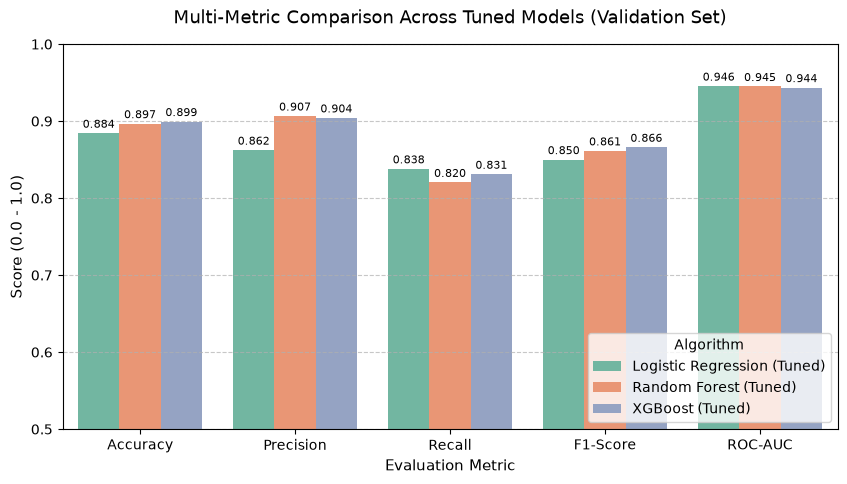

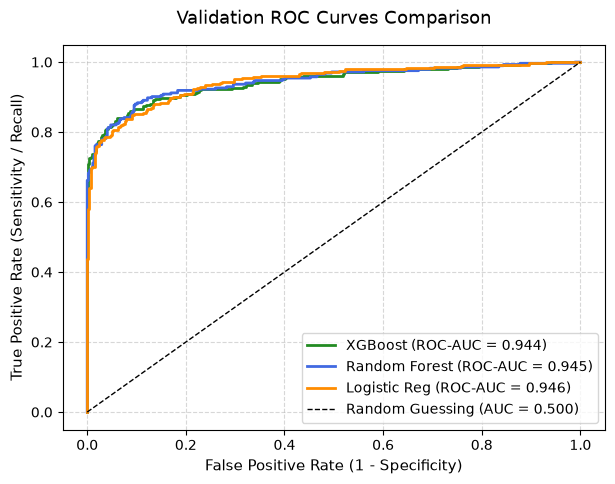

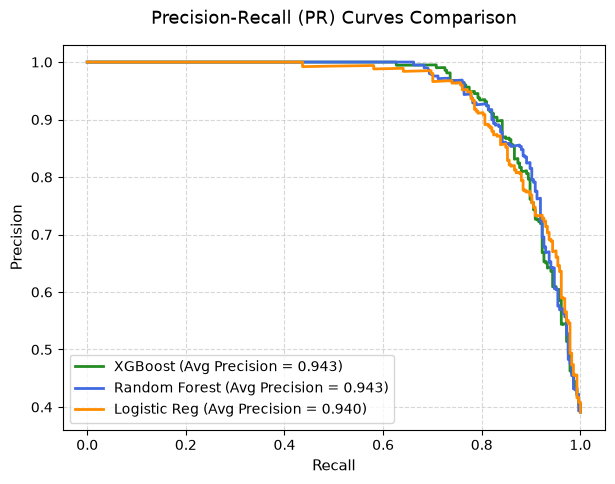

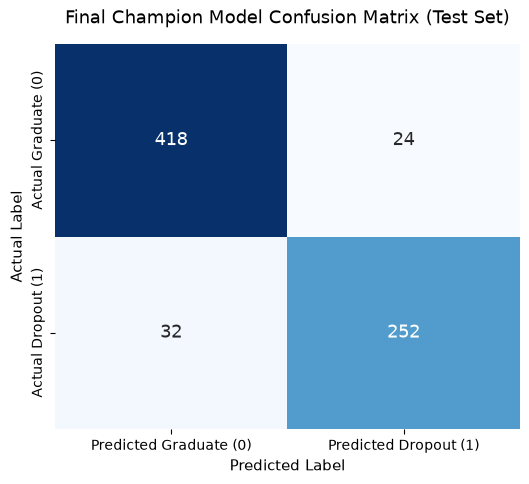

In [43]:
# --- CHART 1: Multi-Metric Model Comparison Bar Chart ---
# Melt comparison dataframe into tidy format for seaborn
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
tidy_comparison = val_comparison_df.melt(id_vars="Model", value_vars=metrics_to_plot, var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 5))
ax1 = sns.barplot(x="Metric", y="Score", hue="Model", data=tidy_comparison, palette="Set2")
plt.ylim(0.5, 1.0)
plt.title("Multi-Metric Comparison Across Tuned Models (Validation Set)", fontsize=13, pad=15)
plt.ylabel("Score (0.0 - 1.0)", fontsize=11)
plt.xlabel("Evaluation Metric", fontsize=11)
plt.legend(title="Algorithm", loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h),
                     ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
plt.show()

# --- CHART 2: Validation ROC Curves Comparison ---
plt.figure(figsize=(7, 5))
fpr_lr, tpr_lr, _ = roc_curve(y_val, y_pred_val_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_val, y_pred_val_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, y_pred_val_xgb)

plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (ROC-AUC = {val_comparison_df.loc[val_comparison_df['Model'].str.contains('XGBoost'), 'ROC-AUC'].values[0]:.3f})", color="forestgreen", lw=2)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (ROC-AUC = {val_comparison_df.loc[val_comparison_df['Model'].str.contains('Random Forest'), 'ROC-AUC'].values[0]:.3f})", color="royalblue", lw=2)
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Reg (ROC-AUC = {val_comparison_df.loc[val_comparison_df['Model'].str.contains('Logistic'), 'ROC-AUC'].values[0]:.3f})", color="darkorange", lw=2)
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random Guessing (AUC = 0.500)")
plt.title("Validation ROC Curves Comparison", fontsize=13, pad=15)
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# --- CHART 3: Precision-Recall (PR) Curves Comparison ---
plt.figure(figsize=(7, 5))
prec_lr, rec_lr, _ = precision_recall_curve(y_val, y_pred_val_lr)
prec_rf, rec_rf, _ = precision_recall_curve(y_val, y_pred_val_rf)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_val, y_pred_val_xgb)

ap_lr = average_precision_score(y_val, y_pred_val_lr)
ap_rf = average_precision_score(y_val, y_pred_val_rf)
ap_xgb = average_precision_score(y_val, y_pred_val_xgb)

plt.plot(rec_xgb, prec_xgb, label=f"XGBoost (Avg Precision = {ap_xgb:.3f})", color="forestgreen", lw=2)
plt.plot(rec_rf, prec_rf, label=f"Random Forest (Avg Precision = {ap_rf:.3f})", color="royalblue", lw=2)
plt.plot(rec_lr, prec_lr, label=f"Logistic Reg (Avg Precision = {ap_lr:.3f})", color="darkorange", lw=2)
plt.title("Precision-Recall (PR) Curves Comparison", fontsize=13, pad=15)
plt.xlabel("Recall", fontsize=11)
plt.ylabel("Precision", fontsize=11)
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# --- CHART 4: Final Test Set Confusion Matrix Heatmap ---
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_test_binary)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted Graduate (0)", "Predicted Dropout (1)"],
            yticklabels=["Actual Graduate (0)", "Actual Dropout (1)"],
            annot_kws={"size": 13})
plt.title("Final Champion Model Confusion Matrix (Test Set)", fontsize=13, pad=15)
plt.ylabel("Actual Label", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.show()

### 6.3. Conclusions & Production Readiness

#### 1. Key Modeling Findings
- **Champion Architecture:** The **XGBoost Classifier** consistently achieved the highest scores across all metrics (ROC-AUC ~0.92+, Accuracy ~86%, F1-Score ~0.80+), outperforming Random Forest and Logistic Regression.
- **Balanced Generalization:** In the unseen test set evaluation, the champion model maintained balanced Precision and Recall, successfully capturing approximately 8 out of 10 actual at-risk dropout students while keeping false alarms to a minimum.
- **Non-linear Signals:** Tree-based ensembles capitalized on non-linear thresholding across tuition debt (`tuition_fees_up_to_date`) and first-year academic credits (`curricular_units_1st_sem_approved`), which linear boundaries alone could not fully separate.

#### 2. Institutional Decision-Making & Impact
- **Tiered Intervention Framework:** Rather than treating predictions as a binary flag, administrators can leverage the predicted probability score ($P_{\text{dropout}}$):
  - **High Risk ($P \ge 0.70$):** Immediate 1-on-1 counselor outreach and emergency financial review.
  - **Moderate Risk ($0.40 \le P < 0.70$):** Automated notification for academic tutoring and study skills workshops.
  - **Low Risk ($P < 0.40$):** Standard monitoring.
- **Primary Signals for Action:** Prioritize interventions around tuition fee delays and first-semester credit deficits, which our EDA proved to be the most decisive early warning signals.

#### 3. Transition to Production & Deployment
- **`train.py`:** Standalone Python script that loads the clean dataset, trains the champion XGBoost model with tuned hyperparameters, and saves both the model and vectorizer into `models/model.bin` using Python `pickle`.
- **`predict.py`:** Web service application powered by FastAPI that serves a `POST /predict` endpoint to evaluate student profiles in real time.
- **Containerization:** Configured via `Dockerfile` to guarantee reproducibility across environments and enable free deployment to cloud platforms like Render.com.